# DOE-037
## エントリ有効性確認

- 対象銘柄: 9984
- 実験計画: 完全実施要因計画 (Full Factorial Design)
- 実験パラメータ
    - PERIOD_MA_1
        - 短周期移動平均線
        - 120, 180, 240, 300, 360
    - PERIOD_MA_2:
        - 長周期移動平均線
        - 1200, 1800, 2400, 3000, 3600
    - 備考
        - データ点数を稼ぐための条件ふり
- 固定パラメータ
    - TYPE_MA_1: EMA
    - START_TRAILING: 35
        - トレーリング・ストップを開始する最大含み益
    - THRESHOLD_TRAILING: 0.90
        - トレーリング・ストップのしきい値比
    - FOLLOWING_MIN: 14
        - 順方向に設定回数以上更新されていて含み損になればロスカット
    - LOSSCUT_SIMPLE: float = -1e10
        - 単純ロスカット（実質的に無効）
- MA1 / MA2 クロス・シグナルのエントリ・エグジット
    - クロス時に反対売買をしない。
- 評価指標
    - 収益と約定回数

In [1]:
from pathlib import Path

import pandas as pd

# === 実験番号 ===
name_doe = "doe-037"

# pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 300)

# 指定したディレクトリのPathオブジェクトを作成
dir_path = Path(f"../doe/{name_doe}")

# .glob() で .csv ファイルのリスト（イテレータ）を取得してリストに変換
list_csv_file = sorted([str(p) for p in dir_path.glob("*.csv") if p.is_file()])

# 集計対象の条件列
columns_group = [
    "TYPE_MA_1",
    "PERIOD_MA_1",
    "PERIOD_MA_2",
]

# CSV ファイルを読み込んで結合
df = pd.concat(
    [
        pd.read_csv(file).assign(
            DATE=pd.to_datetime(Path(file).stem[:8], format="%Y%m%d")
        )
        for file in list_csv_file
    ],
    ignore_index=True,
)

# 条件ごとに Profit を集計
df_total = df.groupby(columns_group, as_index=False).agg(
    Profit_Total=("Profit", "sum"),
    Profit_Mean=("Profit", "mean"),
    Profit_Median=("Profit", "median"),
    Transactions_Median=("Transactions", "median"),
)

print(df)
print("\nSummary Statistics")
print(df_total)
print("\n*** Past", len(list_csv_file), "days statistics ***")
print("\n△ Profit_Total Top 3")
print(df_total.nlargest(3, "Profit_Total"))
print("\n▼ Profit_Total Bottom 3")
print(df_total.nsmallest(3, "Profit_Total"))
print("\n\n△ Profit_Median Top 3")
print(df_total.nlargest(3, "Profit_Median"))
print("\n▼ Profit_Median Bottom 3")
print(df_total.nsmallest(3, "Profit_Median"))

    TYPE_MA_1  PERIOD_MA_1  PERIOD_MA_2  FLAG_SLOPE  START_TRAILING  THRESHOLD_TRAILING  FOLLOWING_MIN  Profit  Transactions       DATE
0         EMA          120         1200        True              35                 0.9             14   -58.0          16.0 2026-09-01
1         EMA          180         1200        True              35                 0.9             14   -67.0          16.0 2026-09-01
2         EMA          240         1200        True              35                 0.9             14   -44.0          12.0 2026-09-01
3         EMA          300         1200        True              35                 0.9             14    -8.0           8.0 2026-09-01
4         EMA          360         1200        True              35                 0.9             14   -14.0           8.0 2026-09-01
..        ...          ...          ...         ...             ...                 ...            ...     ...           ...        ...
745       EMA          120         3600        T

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd

# 指定したディレクトリの Path オブジェクトを作成
dir_transaction_path = Path(f"../doe/{name_doe}") / "transaction"
dir_technicals_path = Path(f"../doe/{name_doe}") / "technicals"

# .glob() で .csv ファイルのリスト（イテレータ）を取得してリストに変換
list_csv_transaction = sorted(
    [str(p) for p in dir_transaction_path.glob("*.csv") if p.is_file()]
)
list_csv_technicals = sorted(
    [str(p) for p in dir_technicals_path.glob("*.csv") if p.is_file()]
)

list_entry = []
cols_technicals = ["ts", "slope_ma1", "slope_ma2", "count_high_pre", "count_low_pre"]
for csv_transaction, csv_technicals in zip(list_csv_transaction, list_csv_technicals):
    df_transaction = pd.read_csv(csv_transaction)
    df_technicals = pd.read_csv(csv_technicals)
    df_technicals = df_technicals[
        df_technicals["ts"].isin(df_transaction["ts"])
    ].reset_index(drop=True)[cols_technicals]

    df_merged = pd.merge(
        df_transaction,
        df_technicals,
        on="ts",
        how="left",
        suffixes=("_transaction", "_technicals"),
    )
    # print(df_merged)

    # 次の行の情報を取得
    df_merged["next_売買"] = df_merged["売買"].shift(-1)
    df_merged["next_ts"] = df_merged["ts"].shift(-1)
    df_merged["next_損益"] = df_merged["損益"].shift(-1)

    # エントリ行を判定
    is_entry = df_merged["売買"].isin(["買建", "売建"])

    # エントリから決済までの時間（秒）
    df_merged["duration"] = (df_merged["next_ts"] - df_merged["ts"]).where(is_entry)

    # 決済時の損益をエントリ行に記録
    df_merged["実現損益"] = df_merged["next_損益"].where(is_entry)

    # エントリ行だけを残す
    df_entry = df_merged.loc[is_entry].copy()

    # 不要な補助列を削除
    df_entry = df_entry.drop(columns=["next_売買", "next_ts", "next_損益"]).reset_index(
        drop=True
    )

    # print(df_entry)
    # リストに追加
    list_entry.append(df_entry)

# すべての DataFrame を結合
df_entries = pd.concat(list_entry, ignore_index=True)
# slope_ma1 と slope_ma2 の交わる角度を算出
df_entries["angle"] = np.degrees(
    np.arctan2(
        np.abs(df_entries["slope_ma1"] - df_entries["slope_ma2"]),
        1 + df_entries["slope_ma1"] * df_entries["slope_ma2"],
    )
)
print(df_entries)

      注文番号                 注文日時  銘柄コード  売買    約定単価  約定数量  損益               備考            ts  slope_ma1  slope_ma2  count_high_pre  count_low_pre     duration  実現損益     angle
0        1  2026-09-01 09:03:41   9984  売建  5093.0     1 NaN    MA デッドクロス（売建）  1.788221e+09  -0.373806  -0.213045               0             26   300.562446 -14.0  8.469256
1        3  2026-09-01 11:11:49   9984  売建  5261.0     1 NaN    MA デッドクロス（売建）  1.788229e+09  -0.015475   0.025459              76             20  5245.378591  -4.0  2.344940
2        5  2026-09-01 12:43:15   9984  売建  5248.0     1 NaN    MA デッドクロス（売建）  1.788234e+09  -0.104613  -0.018869               8             11   372.817722  -9.0  4.891173
3        7  2026-09-01 13:10:21   9984  売建  5243.0     1 NaN    MA デッドクロス（売建）  1.788236e+09  -0.122037   0.022273              10             14   663.227525 -19.0  8.233693
4        9  2026-09-01 13:32:23   9984  売建  5246.0     1 NaN    MA デッドクロス（売建）  1.788237e+09  -0.143301  -0.013386               9 

In [3]:
df_entries_long = (
    df_entries.loc[df_entries["売買"] == "買建"].copy().reset_index(drop=True)
)
print("df_entries_long\n", df_entries_long)
df_entries_short = (
    df_entries.loc[df_entries["売買"] == "売建"].copy().reset_index(drop=True)
)
print("df_entries_short\n", df_entries_short)

df_entries_long
       注文番号                 注文日時  銘柄コード  売買    約定単価  約定数量  損益               備考            ts  slope_ma1  slope_ma2  count_high_pre  count_low_pre     duration  実現損益     angle
0        5  2026-09-01 12:40:22   9984  買建  5271.0     1 NaN  MA ゴールデンクロス（買建）  1.788234e+09   0.131800   0.006633              29             28    38.061277 -16.0  7.128289
1        7  2026-09-01 12:52:02   9984  買建  5267.0     1 NaN  MA ゴールデンクロス（買建）  1.788235e+09   0.090636  -0.008014              11              8   348.830006 -14.0  5.638021
2        9  2026-09-01 13:07:32   9984  買建  5258.0     1 NaN  MA ゴールデンクロス（買建）  1.788236e+09  -0.004553  -0.008906              10              3   170.545029 -17.0  0.249449
3       11  2026-09-01 13:21:04   9984  買建  5259.0     1 NaN  MA ゴールデンクロス（買建）  1.788236e+09   0.106139  -0.001483              16              3   679.244179 -15.0  6.143591
4       13  2026-09-01 13:54:28   9984  買建  5262.0     1 NaN  MA ゴールデンクロス（買建）  1.788238e+09   0.063625  -0.002123

## 買建 (long) の場合

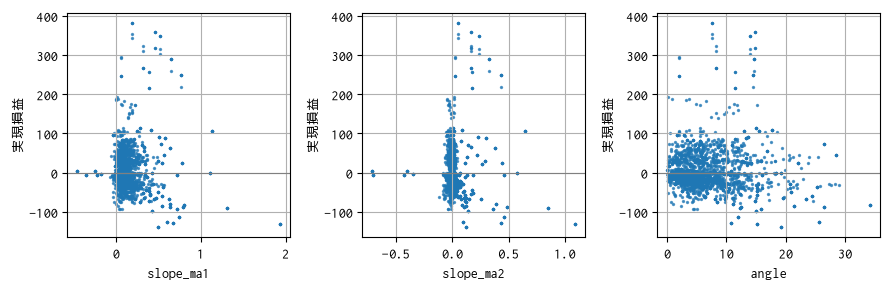

In [4]:
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

FONT_PATH = "../fonts/RictyDiminished-Regular.ttf"
fm.fontManager.addfont(FONT_PATH)

# FontPropertiesオブジェクト生成（名前の取得のため）
font_prop = fm.FontProperties(fname=FONT_PATH)
font_prop.get_name()

plt.rcParams["font.family"] = font_prop.get_name()

fig, axes = plt.subplots(1, 3, figsize=(9, 3))

for ax, col in zip(axes, ["slope_ma1", "slope_ma2", "angle"]):
    ax.scatter(
        df_entries_long[col],
        df_entries_long["実現損益"],
        s=2,
        alpha=0.7,
    )
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_xlabel(col)
    ax.set_ylabel("実現損益")
    ax.grid(True)
    # ax.set_ylim(-100, 100)


plt.tight_layout()
# pngfile = f"../doe/{name_doe}/scatter_long.png"
plt.savefig(pngfile)

plt.show()

In [5]:
cols = ["slope_ma1", "slope_ma2", "angle", "実現損益"]

# Pearson：線形関係
print(df_entries_long[cols].corr(method="pearson"))

# Spearman：順位に基づく単調な関係
print(df_entries_long[cols].corr(method="spearman"))

           slope_ma1  slope_ma2     angle      実現損益
slope_ma1   1.000000   0.848650  0.704788 -0.032046
slope_ma2   0.848650   1.000000  0.243251 -0.008069
angle       0.704788   0.243251  1.000000 -0.019307
実現損益       -0.032046  -0.008069 -0.019307  1.000000
           slope_ma1  slope_ma2     angle      実現損益
slope_ma1   1.000000   0.539504  0.901746 -0.096740
slope_ma2   0.539504   1.000000  0.251063 -0.119296
angle       0.901746   0.251063  1.000000 -0.072461
実現損益       -0.096740  -0.119296 -0.072461  1.000000


In [6]:
import numpy as np

df = df_entries_long.copy()

df["MA1方向"] = np.where(df["slope_ma1"] >= 0, "正", "負")
df["MA2方向"] = np.where(df["slope_ma2"] >= 0, "正", "負")

summary = df.groupby(
    ["MA1方向", "MA2方向"],
    observed=True,
).agg(
    件数=("実現損益", "size"),
    平均損益=("実現損益", "mean"),
    中央値=("実現損益", "median"),
    勝率=("実現損益", lambda s: (s > 0).mean()),
    損益合計=("実現損益", "sum"),
)

summary["勝率"] *= 100

print(summary)

               件数       平均損益   中央値         勝率    損益合計
MA1方向 MA2方向                                          
正     正      1219   3.402789 -11.0  32.649713  4148.0
      負      1010   2.880198  -7.0  36.534653  2909.0
負     正         6  32.166667  -7.0  33.333333   193.0
      負       111   1.693694  -5.0  30.630631   188.0


## 売建 (short) の場合

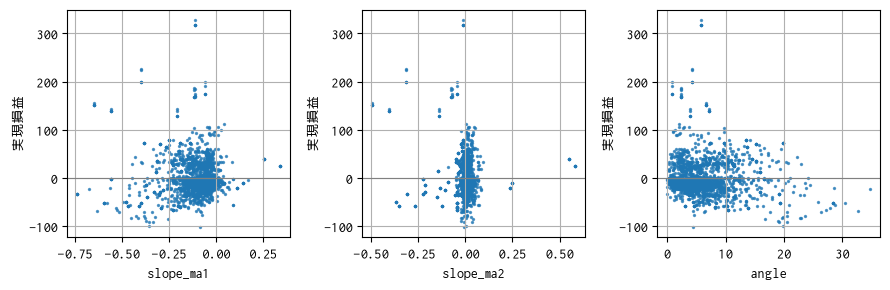

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3))

for ax, col in zip(axes, ["slope_ma1", "slope_ma2", "angle"]):
    ax.scatter(
        df_entries_short[col],
        df_entries_short["実現損益"],
        s=2,
        alpha=0.7,
    )
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_xlabel(col)
    ax.set_ylabel("実現損益")
    ax.grid(True)
    # ax.set_ylim(-100, 100)


plt.tight_layout()
# pngfile = f"../doe/{name_doe}/scatter_short.png"
plt.savefig(pngfile)

plt.show()

In [8]:
cols = ["slope_ma1", "slope_ma2", "angle", "実現損益"]

# Pearson：線形関係
print(df_entries_short[cols].corr(method="pearson"))

# Spearman：順位に基づく単調な関係
print(df_entries_short[cols].corr(method="spearman"))

           slope_ma1  slope_ma2     angle      実現損益
slope_ma1   1.000000   0.650701 -0.756060  0.002314
slope_ma2   0.650701   1.000000 -0.006975 -0.096204
angle      -0.756060  -0.006975  1.000000 -0.088261
実現損益        0.002314  -0.096204 -0.088261  1.000000
           slope_ma1  slope_ma2     angle      実現損益
slope_ma1   1.000000   0.428632 -0.865705  0.056637
slope_ma2   0.428632   1.000000 -0.070358  0.027701
angle      -0.865705  -0.070358  1.000000 -0.045663
実現損益        0.056637   0.027701 -0.045663  1.000000


In [9]:
import numpy as np

df = df_entries_short.copy()

df["MA1方向"] = np.where(df["slope_ma1"] >= 0, "正", "負")
df["MA2方向"] = np.where(df["slope_ma2"] >= 0, "正", "負")

summary = df.groupby(
    ["MA1方向", "MA2方向"],
    observed=True,
).agg(
    件数=("実現損益", "size"),
    平均損益=("実現損益", "mean"),
    中央値=("実現損益", "median"),
    勝率=("実現損益", lambda s: (s > 0).mean()),
    損益合計=("実現損益", "sum"),
)

summary["勝率"] *= 100

print(summary)

              件数      平均損益  中央値         勝率    損益合計
MA1方向 MA2方向                                       
正     正       90  3.422222 -7.5  33.333333   308.0
      負        7 -6.285714 -8.0  14.285714   -44.0
負     正      944 -1.586864 -8.0  32.838983 -1498.0
      負      865  4.127168 -8.0  32.716763  3570.0


## PTC 判定

### 買建 (long) の場合

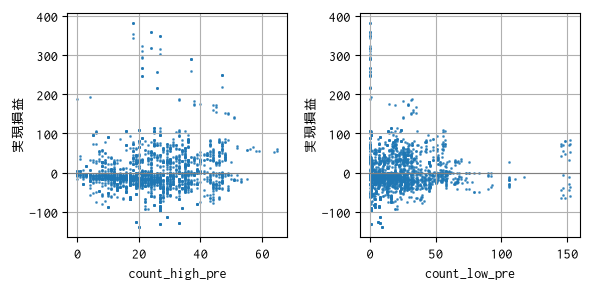

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(6, 3))

for ax, col in zip(axes, ["count_high_pre", "count_low_pre"]):
    ax.scatter(
        df_entries_long[col],
        df_entries_long["実現損益"],
        s=1,
        alpha=0.7,
    )
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_xlabel(col)
    ax.set_ylabel("実現損益")
    ax.grid(True)
    # ax.set_ylim(-100, 100)


plt.tight_layout()
# pngfile = f"../doe/{name_doe}/scatter_short_3.png"
plt.savefig(pngfile)

plt.show()

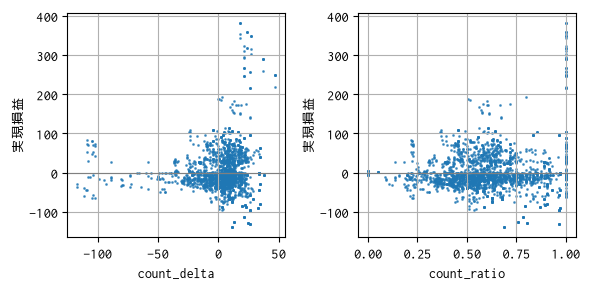

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(6, 3))

df_entries_long["count_delta"] = (
    df_entries_long["count_high_pre"] - df_entries_long["count_low_pre"]
)
df_entries_long["count_ratio"] = df_entries_long["count_high_pre"] / (
    df_entries_long["count_high_pre"] + df_entries_long["count_low_pre"]
)
for ax, col in zip(axes, ["count_delta", "count_ratio"]):
    ax.scatter(
        df_entries_long[col],
        df_entries_long["実現損益"],
        s=1,
        alpha=0.7,
    )
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_xlabel(col)
    ax.set_ylabel("実現損益")
    ax.grid(True)
    # ax.set_ylim(-100, 100)


plt.tight_layout()
# pngfile = f"../doe/{name_doe}/scatter_short.png"
plt.savefig(pngfile)

plt.show()

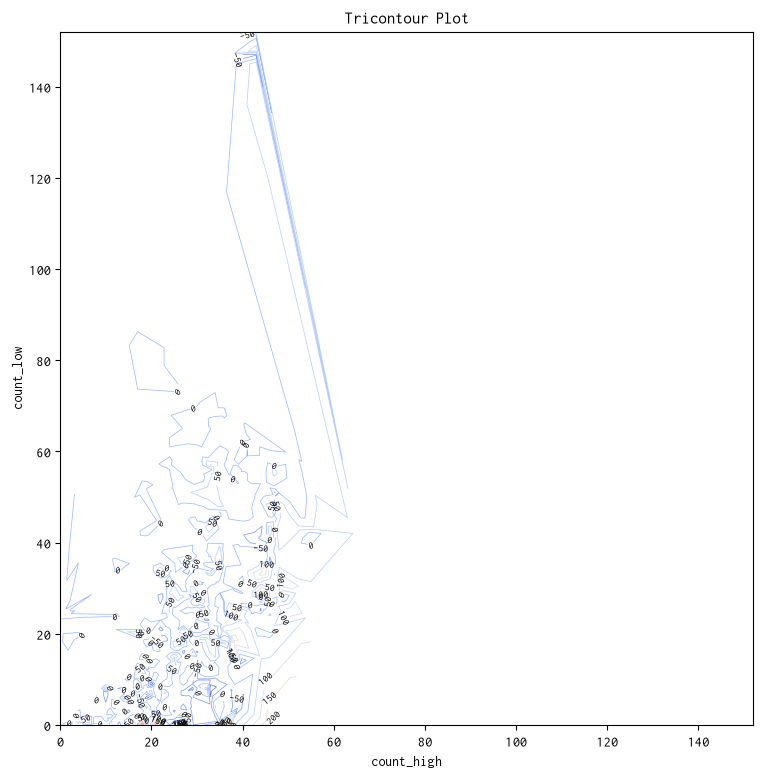

In [17]:
# 1. フィギュアと軸を設定
fig, ax = plt.subplots(1, 1, figsize=(9, 9))

# 1. 線のみの等高線を描画し、戻り値（contours）を受け取る
contours = ax.tricontour(
    df_entries_long["count_high_pre"],
    df_entries_long["count_low_pre"],
    df_entries_long["実現損益"],
    levels=10,
    linewidths=0.5,
    cmap="coolwarm",
)
# plt.colorbar(label="Z value")

# 2. 等高線に z の数字ラベルを付与する
ax.clabel(
    contours,
    inline=True,  # 線をまたぐように数字を埋め込む
    fontsize=7,  # 文字の大きさ
    fmt="%.0f",  # 表示フォーマット（例: %.1f で小数点第1位まで、%d で整数）
    colors="black",  # 文字の色（指定しない場合は等高線の色と同じになります）
)

v_high = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.set_xlim(0, v_high)
ax.set_ylim(0, v_high)

# グラフ領域を 1:1 の正方形にする
ax.set_box_aspect(1)

# 実際のデータポイントを散布図で重ねて確認
# plt.scatter(df["x"], df["y"], color="red", edgecolor="white", s=50)

plt.xlabel("count_high")
plt.ylabel("count_low")
plt.title("Tricontour Plot")
plt.show()

### 売建 (short) の場合

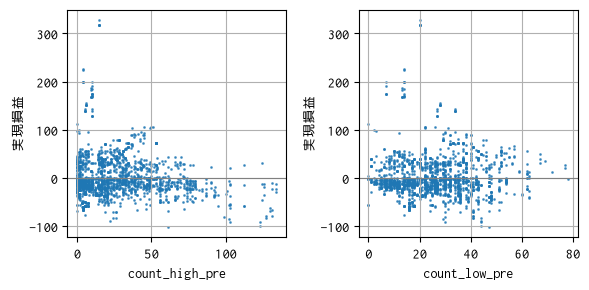

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(6, 3))

for ax, col in zip(axes, ["count_high_pre", "count_low_pre"]):
    ax.scatter(
        df_entries_short[col],
        df_entries_short["実現損益"],
        s=1,
        alpha=0.7,
    )
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_xlabel(col)
    ax.set_ylabel("実現損益")
    ax.grid(True)
    # ax.set_ylim(-100, 100)


plt.tight_layout()
# pngfile = f"../doe/{name_doe}/scatter_short.png"
plt.savefig(pngfile)

plt.show()

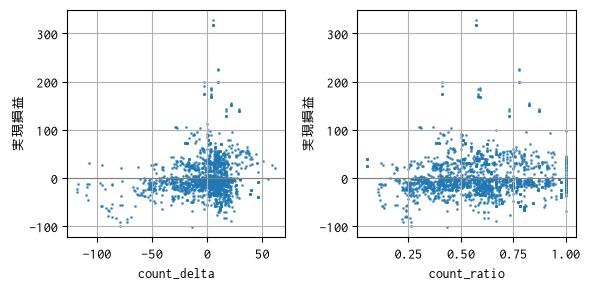

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(6, 3))

df_entries_short["count_delta"] = (
    df_entries_short["count_low_pre"] - df_entries_short["count_high_pre"]
)
df_entries_short["count_ratio"] = df_entries_short["count_low_pre"] / (
    df_entries_short["count_high_pre"] + df_entries_short["count_low_pre"]
)

for ax, col in zip(axes, ["count_delta", "count_ratio"]):
    ax.scatter(
        df_entries_short[col],
        df_entries_short["実現損益"],
        s=1,
        alpha=0.7,
    )
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_xlabel(col)
    ax.set_ylabel("実現損益")
    ax.grid(True)
    # ax.set_ylim(-100, 100)


plt.tight_layout()
# pngfile = f"../doe/{name_doe}/scatter_short.png"
plt.savefig(pngfile)

plt.show()

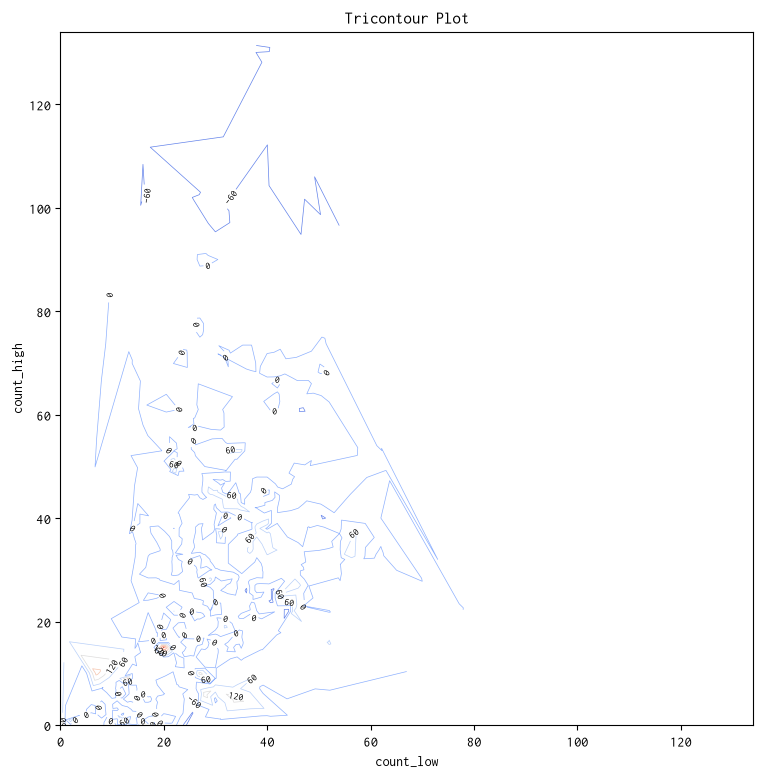

In [18]:
# 1. フィギュアと軸を設定
fig, ax = plt.subplots(1, 1, figsize=(9, 9))

# 1. 線のみの等高線を描画し、戻り値（contours）を受け取る
contours = ax.tricontour(
    df_entries_short["count_low_pre"],
    df_entries_short["count_high_pre"],
    df_entries_short["実現損益"],
    levels=6,
    linewidths=0.5,
    cmap="coolwarm",
)
# plt.colorbar(label="Z value")

# 2. 等高線に z の数字ラベルを付与する
ax.clabel(
    contours,
    inline=True,  # 線をまたぐように数字を埋め込む
    fontsize=7,  # 文字の大きさ
    fmt="%.0f",  # 表示フォーマット（例: %.1f で小数点第1位まで、%d で整数）
    colors="black",  # 文字の色（指定しない場合は等高線の色と同じになります）
)

v_high = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.set_xlim(0, v_high)
ax.set_ylim(0, v_high)

# グラフ領域を 1:1 の正方形にする
ax.set_box_aspect(1)

# 実際のデータポイントを散布図で重ねて確認
# plt.scatter(df["x"], df["y"], color="red", edgecolor="white", s=50)

plt.xlabel("count_low")
plt.ylabel("count_high")
plt.title("Tricontour Plot")
plt.show()